# `Практикум по программированию на языке Python`

## `Задание 1.5. Классификация изображений`.

#### Фамилия, имя: `ВАШЕ ИМЯ`

Дата выдачи: <span style="color:red">__20 февраля__</span>.

Мягкий дедлайн: <span style="color:red">__2 марта 5:00__</span>.

Стоимость: __10 баллов__ (основная часть заданий) + __3 балла__ (дополнительные задания).

<span style="color:red">__В ноутбуке все клетки должны выполняться без ошибок при последовательном их выполнении.__</span>

#### `Москва, 2025`

In [1]:
import random
import numpy as np
from typing import Optional, Tuple, Union, List

from tqdm import tqdm

import torch
from torch import nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
from torchvision import transforms as T

import matplotlib_inline
import matplotlib.pyplot as plt

%matplotlib inline
matplotlib_inline.backend_inline.set_matplotlib_formats('pdf', 'svg')

torch.backends.cudnn.benchmark = True
torch.use_deterministic_algorithms(False)

torch.backends.cudnn.allow_tf32 = True
torch.backends.cuda.matmul.allow_tf32 = True

torch.autograd.profiler.profile(False)
torch.autograd.profiler.emit_nvtx(False)
torch.autograd.set_detect_anomaly(False)

device = torch.device('cuda:0' if torch.cuda.is_available() else 'mps' if torch.mps.is_available() else 'cpu')
print(device)

mps


In [2]:
def set_global_seed(seed: int) -> None:
    """Set global seed for reproducibility.
    :param int seed: Seed to be set
    """
    random.seed(seed)
    np.random.seed(seed)
    
    torch.manual_seed(seed)
    torch.mps.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def check_numel(module: torch.nn.Module, params_numel: int, buffers_numel: Optional[int] = None) -> None:
    """Check whether module has correct number of parameters and buffers
    :param torch.nn.Module module: Target model
    :param int params_numel: Target number of parameters
    :param Optional[int] buffers_numel: Target number of buffers
    :rtype:
    """
    numel = sum(param.numel() for param in module.parameters())
    assert numel == params_numel, f'For params numel != correct numel: {numel} vs {params_numel}'
    
    if buffers_numel is not None:
        numel = sum(param.numel() for param in module.buffers())
        assert numel == buffers_numel, f'For buffers numel != correct numel: {numel} vs {buffers_numel}'

set_global_seed(42)

## `Задание 1. Загрузка данных (0.5 балла)`

В этой домашке работа с данными будет максимально простой. Мы скачаем `MNIST` с помощью [стандартных средств](https://pytorch.org/vision/0.8/datasets.html#mnist) торча. Посмотреть список других доступных датасетов можно [здесь](https://pytorch.org/vision/0.8/datasets.html).

In [3]:
def load_mnist(train, transform=None):    
    if transform is None:
        transform = T.ToTensor()
    return torchvision.datasets.MNIST(
        root='./data',
        train=train,
        transform=transform,
        download=True
    )

Пиксели изображений принимают значения [0,1]. Скачайте датасет и посчитайте выборочное среднее и выборочное стандартное отклонение для значения пикселя. Т.е. должно получиться число `mean` для среднего, и число `std` для стандартного отклонения.

*Подсказка:* Подумайте, на какой части датасета нужно считать эти статистики (обучение или валидация), чтобы предотвратить утечку данных.

*Подсказка:* У торч датасета реализован метод `__getitem__`, т.е. его можно индексировать `dataset[i]`.

In [4]:
data_train = load_mnist(train=True)
data_val = load_mnist(train=False)

cnt = 0

mean = 0
for image, target in data_train:
    mean += image.sum()
    cnt += image.numel()
mean /= cnt

std = 0
for image, train in data_train:
    std += ((image - mean)**2).sum()
std = (std / cnt).sqrt()

print(mean, std)

tensor(0.1307) tensor(0.3081)


Полученные значения можно применить для нормализации изображений, когда будем подавать их в нейросеть.

Нормализация данных в машинном обучении -- это процесс приведения числовых данных к единому масштабу, чтобы они находились в определённом диапазоне (например, от 0 до 1 или со средним 0 и стандартным отклонением 1). Это помогает улучшить скорость и стабильность обучения моделей, особенно когда признаки имеют разный масштаб.

In [5]:
norm_transform = T.Compose([
    T.ToTensor(),
    T.Normalize(mean, std)
])

train_mnist = load_mnist(True, norm_transform)
val_mnist = load_mnist(False, norm_transform)

Во время обучения данные подаются в нейросеть батчами.

Обычно `batch_size` выбирается так, чтобы во время обучения получалась меньше дисперсия градиента (вы уже знакомы с sgd), также часто `batch_size` выбирается максимально возможным по ресурсам.

Для этой задачи нам хватит `batch_size = 64` во время обучения.

**Ответьте на вопрос:** Почему в большинстве задач для валидации и тестирования можно выбирать `batch_size` больше?

**Попытка ответа:** 
- чтобы эффективно параллелить вычисления и быстрее обучаться
- реже чередуется обращение к памяти / вычисление

In [6]:
from torch.utils.data import DataLoader

batch_size_train = 64
batch_size_test = 1000

train_mnist_loader = DataLoader(
    dataset=train_mnist,
    batch_size=batch_size_train,
    shuffle=True,
    drop_last=True
)

val_mnist_loader = torch.utils.data.DataLoader(
    dataset=val_mnist,
    batch_size=batch_size_test,
    shuffle=False,
    drop_last=False
)

In [7]:
images, labels = next(iter(train_mnist_loader))
images.shape, labels.shape

(torch.Size([64, 1, 28, 28]), torch.Size([64]))

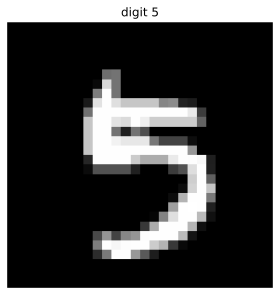

In [8]:
i = 3
plt.title(f'digit {labels[i]}')
plt.imshow(images[i, 0], cmap='gray')
plt.axis('off')
plt.show()

## `Задание 2. Цикл обучения (1.5 балла)`

Ниже предоставлен базовый вариант цикла обучения, представленный тремя функциями: `train_epoch`, `val_epoch`, `train_val`.

In [9]:
def train_epoch(
    network,
    train_loader,
    criterion,
    optimizer,
):
    """train `network` with `optimizer` for one epoch with data from `train_loader` to minimize `criterion`"""

    network = network.to(device)
    network.train()  # switch network submodules to train mode, e.g. it influences on batch-norm, dropout
    for images, labels in train_loader:
        # 0. распакавываем данные на нужное устройство
        images, labels = images.to(device), labels.to(device) # YOUR CODE HERE

        # 1. сбрасываем градиенты предыдущего батча
        optimizer.zero_grad() # YOUR CODE HERE

        # 2. прогоняем данные через нашу нейросеть
        logits = network(images) # YOUR CODE HERE

        # 3. считаем loss
        loss = criterion(logits, labels, reduction='mean') # YOUR CODE HERE

        # 4. считаем градиенты
        loss.backward() # YOUR CODE HERE

        # 5. обновляем параметры
        optimizer.step() # YOUR CODE HERE

In [10]:
@torch.no_grad()
def val_epoch(
    network,
    val_loader,
    criterion,
):
    """calculate loss and accuracy on validation data"""
    val_loss = 0
    correct = 0

    network = network.to(device)
    network.eval()  # switch network submodules to test mode
    for images, labels in val_loader:
        # 0. распакавываем данные на нужное устройство
        images, labels = images.to(device), labels.to(device) # YOUR CODE HERE

        # 1. прогоняем данные через нашу нейросеть
        logits = network(images) # YOUR CODE HERE

         # 2. получаем предсказание
        pred = torch.argmax(logits, dim=1) # YOUR CODE HERE

        # 3. логгируем лосс и accuracy
        val_loss += criterion(logits, labels, reduction='sum').item()
        correct += torch.sum(pred == labels).item()

    val_loss /= len(val_loader.dataset)
    val_accur = correct / len(val_loader.dataset)

    print(
        f'Test set: Avg. loss: {val_loss:.4f}',
        f'Accuracy: {correct}/{len(val_loader.dataset)}',
        f'({100. * val_accur:.0f}%)',
    )

In [11]:
def train_val(
    network,
    n_epochs,
    criterion,
    optimizer,
    train_loader,
    val_loader,
):
    """full cycle of neural network training"""

    val_epoch(network, val_loader, criterion)
    for epoch in range(1, n_epochs + 1):
        train_epoch(network, train_loader, criterion, optimizer)
        val_epoch(network, val_loader, criterion)

Для проверки, что все работает, обучите бейзлайн -- однослойную [полносвязную](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html) сеть на [кросс-энтропийный лосс](https://pytorch.org/docs/stable/generated/torch.nn.functional.cross_entropy.html). 


*Заметьте*, что на вход этому лоссу нужно подавать сырой выход нейросети, а не результат применения софтмакса.

*Подсказка:* Не забудьте вытянуть картинку в вектор с помощью `torch.nn.Flatten()`.

In [12]:
class LogReg(nn.Module):
    def __init__(self):
        super().__init__()

        self.flatten = torch.nn.Flatten()
        self.linear = torch.nn.Linear(in_features=28 * 28, out_features=10)

    def forward(self, x):
        
        x = self.flatten(x)
        x = self.linear(x)

        return x

In [13]:
net = LogReg()
check_numel(net, 7850)

In [14]:
optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)

train_val(
    network=net,
    n_epochs=5,
    criterion=torch.nn.functional.cross_entropy,
    optimizer=optimizer,
    train_loader=train_mnist_loader,
    val_loader=val_mnist_loader
)

Test set: Avg. loss: 2.4444 Accuracy: 1432/10000 (14%)
Test set: Avg. loss: 0.2954 Accuracy: 9174/10000 (92%)
Test set: Avg. loss: 0.2802 Accuracy: 9229/10000 (92%)
Test set: Avg. loss: 0.2792 Accuracy: 9201/10000 (92%)
Test set: Avg. loss: 0.2696 Accuracy: 9242/10000 (92%)
Test set: Avg. loss: 0.2738 Accuracy: 9227/10000 (92%)


## `Задание 3. Логирование (3 балл)`

Скопируйте и перепишите функции `train_epoch`, `val_epoch`, `train_val` таким образом, чтобы
- во время обучения раз в `logging_interval` шагов оптимизации выводились лосс и accuracy на одном батче (пример ниже, но не обязательно делать идентично)
- происходило сохранение весов лучшей (по accuracy на валидации) модели и состояния оптимизатора ([в помощь](https://pytorch.org/tutorials/beginner/saving_loading_models.html#save-load-state-dict-recommended))
- в конце обучения выводился и сохранялся график-саммари (пример ниже, но не обязательно делать идентично)

**Ответьте на вопрос:** Что хранится в состоянии оптимизатора? Зачем нужно его сохранять? Приведите хотя бы один пример оптимизатора, для которого есть смысл сохранять состояние.

**Ответ:**
- оптимизатор может хранить число шагов, усредненную норму градиента и уйму других параметров
- например, есть Adam, которому надо хранить число шагов, накопленный градиент и накопленные квадраты градиента

In [15]:
from pathlib import Path
from time import perf_counter

def train_epoch(
    network,
    train_loader,
    criterion,
    optimizer,
    logging_interval,
    epoch,
    epochs,
    train_loss,
):
    """train `network` with `optimizer` for one epoch with data from `train_loader` to minimize `criterion`"""

    network = network.to(device)
    network.train()  # switch network submodules to train mode, e.g. it influences on batch-norm, dropout
    step = 0
    processed = 0
    for images, labels in train_loader:
        # 0. распакавываем данные на нужное устройство
        images, labels = images.to(device), labels.to(device) # YOUR CODE HERE

        # 1. сбрасываем градиенты предыдущего батча
        optimizer.zero_grad() # YOUR CODE HERE

        # 2. прогоняем данные через нашу нейросеть
        logits = network(images) # YOUR CODE HERE

        # 3. считаем loss
        loss = criterion(logits, labels, reduction='mean') # YOUR CODE HERE

        # 4. считаем градиенты
        loss.backward() # YOUR CODE HERE

        # 5. обновляем параметры
        optimizer.step() # YOUR CODE HERE

        if step % logging_interval == 0:
            epochs.append(epoch - 1 + processed/len(train_mnist))
            train_loss.append(loss.item())
            print(f"Train Epoch: {epoch}\t\t[{processed}/{len(train_mnist)} ({100 * processed/len(train_mnist):.0f}%)]\t\tLoss: {loss:.6f}")

        step += 1
        processed += len(images)
    print()

@torch.no_grad()
def val_epoch(
    network,
    val_loader,
    criterion,
    epoch,
    test_epochs,
    test_loss,
    time,
    accuracy,
):
    """calculate loss and accuracy on validation data"""
    val_loss = 0
    correct = 0

    network = network.to(device)
    network.eval()  # switch network submodules to test mode
    for images, labels in val_loader:
        # 0. распакавываем данные на нужное устройство
        images, labels = images.to(device), labels.to(device) # YOUR CODE HERE

        # 1. прогоняем данные через нашу нейросеть
        logits = network(images) # YOUR CODE HERE

         # 2. получаем предсказание
        pred = torch.argmax(logits, dim=1) # YOUR CODE HERE

        # 3. логгируем лосс и accuracy
        val_loss += criterion(logits, labels, reduction='sum').item()
        correct += torch.sum(pred == labels).item()

    val_loss /= len(val_loader.dataset)
    val_accur = correct / len(val_loader.dataset)

    test_epochs.append(epoch)
    test_loss.append(val_loss)

    time.append(perf_counter())
    accuracy.append(val_accur)

    print(
        f'Validation set: Avg. loss: {val_loss:.4f} Accuracy: {correct}/{len(val_loader.dataset)} ({100. * val_accur:.0f}%)',
    )
    print()

    return val_accur, val_loss

def save_model(
    network, 
    optimizer,
    exp_name,
    val_accur,
    val_loss,
):
    Path("./exps/").mkdir(parents=True, exist_ok=True)
    torch.save({
        'model_state_dict': network.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'val_accur': val_accur,
        'val_loss': val_loss,
        }, f'./exps/{exp_name}')

def train_val(
    network,
    n_epochs,
    logging_interval,
    criterion,
    optimizer,
    train_loader,
    val_loader,
    exp_name,
    model_name,
):
    """full cycle of neural network training"""

    epochs = []
    train_loss = []

    test_epochs = []
    test_loss = []

    time = []
    accuracy = []

    start = perf_counter()

    best_accur = 0
    val_accur, val_loss = val_epoch(network, val_loader, criterion, 0, test_epochs, test_loss, time, accuracy)
    if val_accur > best_accur:
        best_accur = val_accur
        save_model(network, optimizer, exp_name, val_accur, val_loss)

    for epoch in range(1, n_epochs + 1):
        train_epoch(network, train_loader, criterion, optimizer, logging_interval, epoch, epochs, train_loss)
        val_accur, val_loss = val_epoch(network, val_loader, criterion, epoch, test_epochs, test_loss, time, accuracy)
        if val_accur > best_accur:
            best_accur = val_accur
            save_model(network, optimizer, exp_name, val_accur, val_loss)

    for i in range(len(time)):
        time[i] = time[i] - start

    #plot by chatgpt
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(epochs, train_loss, label="Train Loss")
    axes[0].plot(test_epochs, test_loss, "o-", label="Test Loss")

    axes[0].set_xlabel("epochs completed")
    axes[0].set_ylabel("loss")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(time, accuracy, "o-", color="green")

    axes[1].set_xlabel("time, s")
    axes[1].set_ylabel("accuracy")
    axes[1].grid(True)

    fig.suptitle(f"{model_name} (best accuracy {100 * best_accur:.2f}%, total time {time[-1]:.2f} s)")

    plt.tight_layout()
    fig.savefig(f"./exps/{exp_name}_metrics.png", dpi=300, bbox_inches="tight")
    plt.show()


Validation set: Avg. loss: 2.3793 Accuracy: 856/10000 (9%)

Train Epoch: 1		[0/60000 (0%)]		Loss: 2.454835
Train Epoch: 1		[19200/60000 (32%)]		Loss: 0.298491
Train Epoch: 1		[38400/60000 (64%)]		Loss: 0.442020
Train Epoch: 1		[57600/60000 (96%)]		Loss: 0.539971

Validation set: Avg. loss: 0.2892 Accuracy: 9162/10000 (92%)

Train Epoch: 2		[0/60000 (0%)]		Loss: 0.203942
Train Epoch: 2		[19200/60000 (32%)]		Loss: 0.443896
Train Epoch: 2		[38400/60000 (64%)]		Loss: 0.213430
Train Epoch: 2		[57600/60000 (96%)]		Loss: 0.405581

Validation set: Avg. loss: 0.2751 Accuracy: 9241/10000 (92%)

Train Epoch: 3		[0/60000 (0%)]		Loss: 0.336639
Train Epoch: 3		[19200/60000 (32%)]		Loss: 0.258552
Train Epoch: 3		[38400/60000 (64%)]		Loss: 0.367565
Train Epoch: 3		[57600/60000 (96%)]		Loss: 0.183100

Validation set: Avg. loss: 0.2722 Accuracy: 9238/10000 (92%)

Train Epoch: 4		[0/60000 (0%)]		Loss: 0.199589
Train Epoch: 4		[19200/60000 (32%)]		Loss: 0.326135
Train Epoch: 4		[38400/60000 (64%)]		Loss: 

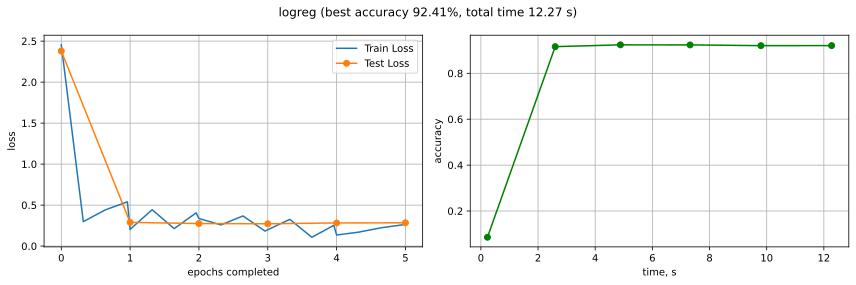

In [16]:
net = LogReg()
check_numel(net, 7850)

optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)

train_val(
    network=net,
    n_epochs=5,
    logging_interval=300,
    criterion=torch.nn.functional.cross_entropy,
    optimizer=optimizer,
    train_loader=train_mnist_loader,
    val_loader=val_mnist_loader,
    exp_name="logs",
    model_name="logreg",
)

Загрузите лучшие веса модели и подсчитайте accuracy на валидации, чтобы подтвердить что веса сохранились корректно.

In [17]:
checkpoint = torch.load('./exps/logs', weights_only=True)
net.load_state_dict(checkpoint['model_state_dict'])
optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
val_accur = checkpoint['val_accur']
val_loss = checkpoint['val_loss']

print(f"Saved:\n Accuracy = {val_accur}\n Loss = {val_loss}")
print()
nv_accur, nv_loss = val_epoch(net, val_mnist_loader, torch.nn.functional.cross_entropy, 0, [], [], [], [])
print(f"New:\n Accuracy = {nv_accur}\n Loss = {nv_loss}")

Saved:
 Accuracy = 0.9241
 Loss = 0.27513401641845703

Validation set: Avg. loss: 0.2751 Accuracy: 9241/10000 (92%)

New:
 Accuracy = 0.9241
 Loss = 0.27513401641845703


Загрузите сохранённое состояние оптимизатора и сделайте две эпохи обучения, чтобы подтвердить, что состояния оптимизатора были сохранены корректно.

Validation set: Avg. loss: 0.2751 Accuracy: 9241/10000 (92%)

Train Epoch: 1		[0/60000 (0%)]		Loss: 0.106902
Train Epoch: 1		[19200/60000 (32%)]		Loss: 0.408827
Train Epoch: 1		[38400/60000 (64%)]		Loss: 0.317060
Train Epoch: 1		[57600/60000 (96%)]		Loss: 0.212616

Validation set: Avg. loss: 0.2761 Accuracy: 9243/10000 (92%)

Train Epoch: 2		[0/60000 (0%)]		Loss: 0.163351
Train Epoch: 2		[19200/60000 (32%)]		Loss: 0.049858
Train Epoch: 2		[38400/60000 (64%)]		Loss: 0.577281
Train Epoch: 2		[57600/60000 (96%)]		Loss: 0.179068

Validation set: Avg. loss: 0.2764 Accuracy: 9253/10000 (93%)



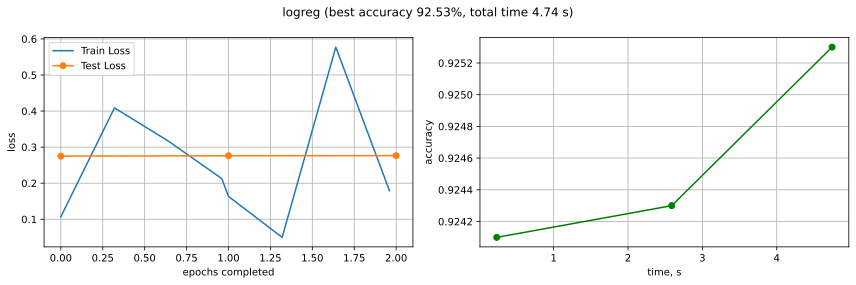

In [18]:
train_val(
    network=net,
    n_epochs=2,
    logging_interval=300,
    criterion=torch.nn.functional.cross_entropy,
    optimizer=optimizer,
    train_loader=train_mnist_loader,
    val_loader=val_mnist_loader,
    exp_name="logs",
    model_name="logreg"
)

## `Задание 4. Логирование с помощью tensorboard (1 балл)`

На самом деле это дурной тон логировать обучение нейросети так, как это сделали вы выше. Дело в том, что весь функционал уже реализован в [`tensorboard`](https://pytorch.org/docs/stable/tensorboard.html), а вы написали велосипед.

In [19]:
# ! pip3 install tensorboard
from torch.utils.tensorboard import SummaryWriter

Если у вас есть доступ к терминалу и браузеру, то удобнее всего ввести команду
```bash
tensorboard --logdir .
```
и открыть UI в выделенном локалхосте. 

Если вы работаете в гугл колабе, то можете запустить UI как виджет в Jupyter:

In [20]:
# %load_ext tensorboard
# %tensorboard --logdir .

Как только вы начнете логировать в объект типа `SummaryWriter`, в UI начнут строиться кривые обучения.

Скопируйте и перепишите функции обучения таким образом, чтобы логирование происходило в `tensorboard`.

*Замечание.* Вам пригодится метод `add_scalar`, чтобы сохранять лосс и accuracy, и метод `add_hparams`, чтобы сохранить важные гиперпараметры (например, кодовое имя архитектуры сети) и финальное достигнутое качество.

In [21]:
from pathlib import Path
from time import perf_counter

def train_epoch(
    network,
    train_loader,
    criterion,
    optimizer,
    writer,
    logging_interval,
    epoch,
    steps,
):
    """train `network` with `optimizer` for one epoch with data from `train_loader` to minimize `criterion`"""

    network = network.to(device)
    network.train()  # switch network submodules to train mode, e.g. it influences on batch-norm, dropout
    step = 0
    processed = 0
    for images, labels in train_loader:
        # 0. распакавываем данные на нужное устройство
        images, labels = images.to(device), labels.to(device) # YOUR CODE HERE

        # 1. сбрасываем градиенты предыдущего батча
        optimizer.zero_grad() # YOUR CODE HERE

        # 2. прогоняем данные через нашу нейросеть
        logits = network(images) # YOUR CODE HERE

        # 3. считаем loss
        loss = criterion(logits, labels, reduction='mean') # YOUR CODE HERE

        # 4. считаем градиенты
        loss.backward() # YOUR CODE HERE

        # 5. обновляем параметры
        optimizer.step() # YOUR CODE HERE

        if step % logging_interval == 0:
            writer.add_scalar(
                "train/loss",
                loss,
                steps + step,
            )

        step += 1
        processed += len(images)

    network.eval()
    with torch.no_grad():
        correct = 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            logits = network(images)
            pred = torch.argmax(logits, dim=1)
            correct += torch.sum(pred == labels).item()
        accuracy = correct / len(train_loader.dataset)

        writer.add_scalar(
            "train/accur",
            accuracy,
            epoch,
        )

    return step

@torch.no_grad()
def val_epoch(
    network,
    val_loader,
    criterion,
    writer,
    epoch,
):
    """calculate loss and accuracy on validation data"""
    val_loss = 0
    correct = 0

    network = network.to(device)
    network.eval()  # switch network submodules to test mode
    for images, labels in val_loader:
        # 0. распакавываем данные на нужное устройство
        images, labels = images.to(device), labels.to(device) # YOUR CODE HERE

        # 1. прогоняем данные через нашу нейросеть
        logits = network(images) # YOUR CODE HERE

         # 2. получаем предсказание
        pred = torch.argmax(logits, dim=1) # YOUR CODE HERE

        # 3. логгируем лосс и accuracy
        val_loss += criterion(logits, labels, reduction='sum').item()
        correct += torch.sum(pred == labels).item()

    val_loss /= len(val_loader.dataset)
    val_accur = correct / len(val_loader.dataset)

    writer.add_scalar(
        "test/loss",
        val_loss,
        epoch
    )

    writer.add_scalar(
        "test/accur",
        val_accur,
        epoch,
    )

    return val_accur, val_loss

def save_model(
    network, 
    optimizer,
    exp_name,
    val_accur,
    val_loss,
):
    Path("./exps/").mkdir(parents=True, exist_ok=True)
    torch.save({
        'model_state_dict': network.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'val_accur': val_accur,
        'val_loss': val_loss,
        }, f'./exps/{exp_name}')

def train_val(
    network,
    n_epochs,
    logging_interval,
    criterion,
    optimizer,
    train_loader,
    val_loader,
    exp_name,
    model_name,
):
    """full cycle of neural network training"""

    writer = SummaryWriter(f"runs/{exp_name}")

    best_accur = 0
    val_accur, val_loss = val_epoch(network, val_loader, criterion, writer, 0)
    if val_accur > best_accur:
        best_accur = val_accur
        save_model(network, optimizer, exp_name, val_accur, val_loss)

    step_cnt = 0
    for epoch in tqdm(range(1, n_epochs + 1), ):
        step_cnt += train_epoch(network, train_loader, criterion, optimizer, writer, logging_interval, epoch, step_cnt)
        val_accur, val_loss = val_epoch(network, val_loader, criterion, writer, epoch)
        if val_accur > best_accur:
            best_accur = val_accur
            save_model(network, optimizer, exp_name, val_accur, val_loss)

    hparams = {'model': model_name, 'struct' : str(network)}
    metrics = {'best_accuracy' : best_accur}
    writer.add_hparams(hparams, metrics)

    writer.close()

In [22]:
net = LogReg()
check_numel(net, 7850)

optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)

train_val(
    network=net,
    n_epochs=5,
    logging_interval=300,
    criterion=torch.nn.functional.cross_entropy,
    optimizer=optimizer,
    train_loader=train_mnist_loader,
    val_loader=val_mnist_loader,
    exp_name="tensorboard",
    model_name="logreg",
)

100%|██████████| 5/5 [00:20<00:00,  4.18s/it]


## `Задание 5. Побейте бейзлайн (2+2 балла)`

На датасете [`CIFAR-10`](https://pytorch.org/vision/0.8/datasets.html#torchvision.datasets.CIFAR10) обучите модель, которая выдает accuracy `>=0.7` (2 балла) и accuracy `>=0.8` (ещё 2 балла).
- Можете использовать любые модули `pytorch`, любые оптимизаторы и шедулеры, можете использовать аугментации ([например](https://pytorch.org/vision/stable/transforms.html))
- Для отслеживания экспериментов используйте логирование с `tensorboard`, не забывайте давать осмысленные имена эспериментам и логировать нужные гиперпараметры, сохранять веса сети и состояние оптимизатора.

In [23]:
def load_cifar10(train, transform=None):    
    if transform is None:
        transform = T.ToTensor()
    return torchvision.datasets.CIFAR10(
        root='./data',
        train=train,
        transform=transform,
        download=True
    )

In [24]:
data_train = load_cifar10(train=True)
data_val = load_cifar10(train=False)

cnt = 0

mean = 0
for image, target in data_train:
    mean += image.sum(dim=[1,2])
    cnt += image.shape[1] * image.shape[2]
mean /= cnt

std = 0
for image, train in data_train:
    std += ((image - mean[:, None, None])**2).sum(dim=[1,2])
std = (std / cnt).sqrt()

print(mean, std)

tensor([0.4914, 0.4822, 0.4465]) tensor([0.2470, 0.2435, 0.2616])


In [25]:
norm_transform = T.Compose([
    T.ToTensor(),
    T.Normalize(mean, std)
])

train_cifar10 = load_cifar10(True, norm_transform)
val_cifar10 = load_cifar10(False, norm_transform)

In [26]:
from torch.utils.data import DataLoader

batch_size_train = 64
batch_size_test = 1000

train_cifar10_loader = DataLoader(
    dataset=train_cifar10,
    batch_size=batch_size_train,
    shuffle=True,
    drop_last=True
)

val_cifar10_loader = torch.utils.data.DataLoader(
    dataset=val_cifar10,
    batch_size=batch_size_test,
    shuffle=False,
    drop_last=False
)

In [27]:
images, labels = next(iter(train_cifar10_loader))
images.shape, labels.shape

(torch.Size([64, 3, 32, 32]), torch.Size([64]))

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.8145914..2.1267948].


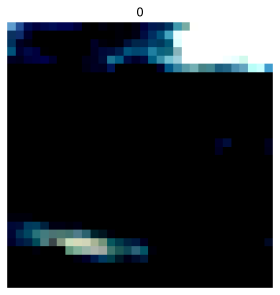

In [28]:
i = 3
plt.title(f'{labels[i]}')
plt.imshow(images[i].permute(1, 2, 0))
plt.axis('off')
plt.show()

In [29]:
class MyNetwork_v1(nn.Module):
    def __init__(self):
        super().__init__()

        self.flatten = torch.nn.Flatten()

        self.in_layer = torch.nn.Sequential(
            torch.nn.Linear(in_features=3 * 32 * 32, out_features=100),
            torch.nn.BatchNorm1d(num_features=100),
            torch.nn.ReLU(),
        )

        self.hidden = torch.nn.Sequential(
            torch.nn.Linear(in_features=100, out_features=100),
            torch.nn.BatchNorm1d(num_features=100),
            torch.nn.ReLU(),
        )

        self.out_layer = torch.nn.Sequential(
            torch.nn.Linear(in_features=100, out_features=10),
        )

    def forward(self, x):
        x = self.flatten(x)
        x = self.in_layer(x)
        x = self.hidden(x)
        x = self.out_layer(x)

        return x

In [30]:
net = MyNetwork_v1()

optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)

train_val(
    network=net,
    n_epochs=15,
    logging_interval=300,
    criterion=torch.nn.functional.cross_entropy,
    optimizer=optimizer,
    train_loader=train_cifar10_loader,
    val_loader=val_cifar10_loader,
    exp_name="First run",
    model_name="mynetwork_v1",
)

100%|██████████| 15/15 [01:20<00:00,  5.34s/it]


In [31]:
class MyNetwork_v2(nn.Module):
    def __init__(self):
        super().__init__()

        self.flatten = torch.nn.Flatten()

        self.in_layer = torch.nn.Sequential(
            torch.nn.Linear(in_features=3 * 32 * 32, out_features=100),
            torch.nn.BatchNorm1d(num_features=100),
            torch.nn.ReLU(),
            torch.nn.Dropout(p=0.2),
        )

        self.hidden = torch.nn.Sequential(
            torch.nn.Linear(in_features=100, out_features=100),
            torch.nn.BatchNorm1d(num_features=100),
            torch.nn.ReLU(),
            torch.nn.Dropout(p=0.2),
        )

        self.out_layer = torch.nn.Sequential(
            torch.nn.Linear(in_features=100, out_features=10),
        )

    def forward(self, x):
        x = self.flatten(x)
        x = self.in_layer(x)
        x = self.hidden(x)
        x = self.out_layer(x)

        return x

In [32]:
net = MyNetwork_v2()

optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)

train_val(
    network=net,
    n_epochs=20,
    logging_interval=300,
    criterion=torch.nn.functional.cross_entropy,
    optimizer=optimizer,
    train_loader=train_cifar10_loader,
    val_loader=val_cifar10_loader,
    exp_name="Added dropout",
    model_name="mynetwork_v2",
)

100%|██████████| 20/20 [01:48<00:00,  5.41s/it]


In [33]:
class MyNetwork_v3(nn.Module):
    def __init__(self):
        super().__init__()

        self.flatten = torch.nn.Flatten()

        self.in_layer = torch.nn.Sequential(
            torch.nn.Linear(in_features=3 * 32 * 32, out_features=100),
            torch.nn.BatchNorm1d(num_features=100),
            torch.nn.ReLU(),
            torch.nn.Dropout(p=0.2),
        )

        self.hidden = torch.nn.Sequential(
            torch.nn.Linear(in_features=100, out_features=100),
            torch.nn.BatchNorm1d(num_features=100),
            torch.nn.ReLU(),
            torch.nn.Dropout(p=0.2),

            torch.nn.Linear(in_features=100, out_features=100),
            torch.nn.BatchNorm1d(num_features=100),
            torch.nn.ReLU(),
            torch.nn.Dropout(p=0.2),

            torch.nn.Linear(in_features=100, out_features=100),
            torch.nn.BatchNorm1d(num_features=100),
            torch.nn.ReLU(),
            torch.nn.Dropout(p=0.2),
        )

        self.out_layer = torch.nn.Sequential(
            torch.nn.Linear(in_features=100, out_features=10),
        )

    def forward(self, x):
        x = self.flatten(x)
        x = self.in_layer(x)
        x = self.hidden(x)
        x = self.out_layer(x)

        return x

In [34]:
net = MyNetwork_v3()

optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)

train_val(
    network=net,
    n_epochs=20,
    logging_interval=300,
    criterion=torch.nn.functional.cross_entropy,
    optimizer=optimizer,
    train_loader=train_cifar10_loader,
    val_loader=val_cifar10_loader,
    exp_name="Increased number of layers",
    model_name="mynetwork_v3",
)

100%|██████████| 20/20 [02:05<00:00,  6.26s/it]


In [35]:
class MyNetwork_v4(nn.Module):
    def __init__(self):
        super().__init__()

        self.flatten = torch.nn.Flatten()

        self.in_layer = torch.nn.Sequential(
            torch.nn.Linear(in_features=3 * 32 * 32, out_features=200),
            torch.nn.BatchNorm1d(num_features=200),
            torch.nn.ReLU(),
            torch.nn.Dropout(p=0.2),
        )

        self.hidden = torch.nn.Sequential(
            *[
                torch.nn.Sequential(
                    torch.nn.Linear(in_features=200, out_features=200),
                    torch.nn.BatchNorm1d(num_features=200),
                    torch.nn.ReLU(),
                    torch.nn.Dropout(p=0.2),
                )
                for _ in range(3)
            ]
        )

        self.out_layer = torch.nn.Sequential(
            torch.nn.Linear(in_features=200, out_features=10),
        )

    def forward(self, x):
        x = self.flatten(x)
        x = self.in_layer(x)
        x = self.hidden(x)
        x = self.out_layer(x)

        return x

In [36]:
net = MyNetwork_v4()

optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)

train_val(
    network=net,
    n_epochs=20,
    logging_interval=300,
    criterion=torch.nn.functional.cross_entropy,
    optimizer=optimizer,
    train_loader=train_cifar10_loader,
    val_loader=val_cifar10_loader,
    exp_name="Increased size of hidden layers",
    model_name="mynetwork_v4",
)

100%|██████████| 20/20 [02:06<00:00,  6.31s/it]


In [37]:
train_transform = T.Compose([
    T.RandomHorizontalFlip(p=0.5),
    T.RandomVerticalFlip(p=0.5),
    T.RandomCrop((32, 32), padding=3),
    T.ToTensor(),
    T.Normalize(mean, std),
])

val_transform = T.Compose([
    T.ToTensor(),
    T.Normalize(mean, std),
])

train_cifar10 = load_cifar10(True, train_transform)
val_cifar10 = load_cifar10(False, val_transform)

In [38]:
from torch.utils.data import DataLoader

batch_size_train = 64
batch_size_test = 1000

train_cifar10_loader = DataLoader(
    dataset=train_cifar10,
    batch_size=batch_size_train,
    shuffle=True,
    drop_last=True
)

val_cifar10_loader = torch.utils.data.DataLoader(
    dataset=val_cifar10,
    batch_size=batch_size_test,
    shuffle=False,
    drop_last=False
)

In [39]:
net = MyNetwork_v4()

optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)

train_val(
    network=net,
    n_epochs=20,
    logging_interval=300,
    criterion=torch.nn.functional.cross_entropy,
    optimizer=optimizer,
    train_loader=train_cifar10_loader,
    val_loader=val_cifar10_loader,
    exp_name="Added augmentations",
    model_name="mynetwork_v4",
)

100%|██████████| 20/20 [02:52<00:00,  8.64s/it]


In [40]:
class MyNetwork_v5(nn.Module):
    def __init__(self):
        super().__init__()

        self.convs = torch.nn.Sequential(
            *[
                torch.nn.Sequential(
                    torch.nn.Conv2d(in_channels=3, out_channels=3, kernel_size=3),
                    torch.nn.MaxPool2d(kernel_size=3, stride=1, padding=1),
                )
                for _ in range(3)
            ]
        )

        self.flatten = torch.nn.Flatten()

        self.head = torch.nn.Linear(in_features=2028, out_features=10)

    def forward(self, x):
        x = self.convs(x)
        x = self.flatten(x)
        x = self.head(x)

        return x

In [41]:
net = MyNetwork_v5()

optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)

train_val(
    network=net,
    n_epochs=20,
    logging_interval=300,
    criterion=torch.nn.functional.cross_entropy,
    optimizer=optimizer,
    train_loader=train_cifar10_loader,
    val_loader=val_cifar10_loader,
    exp_name="It is CNN with MaxPool now",
    model_name="mynetwork_v5",
)

100%|██████████| 20/20 [02:37<00:00,  7.87s/it]


In [42]:
class MyNetwork_v6(nn.Module):
    def __init__(self):
        super().__init__()

        self.in_conv = torch.nn.Conv2d(in_channels=3, out_channels=10, kernel_size=3, stride=2)

        self.convs = torch.nn.Sequential(
            *[
                torch.nn.Sequential(
                    torch.nn.Conv2d(in_channels=10, out_channels=10, kernel_size=3, stride=1),
                    torch.nn.MaxPool2d(kernel_size=3, stride=1, padding=1),
                )
                for _ in range(4)
            ]
        )

        self.out_layer = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(1)
        )

    def forward(self, x):
        x = self.in_conv(x)
        x = self.convs(x)
        x = self.out_layer(x)

        return x

In [43]:
net = MyNetwork_v6()

optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)

train_val(
    network=net,
    n_epochs=20,
    logging_interval=300,
    criterion=torch.nn.functional.cross_entropy,
    optimizer=optimizer,
    train_loader=train_cifar10_loader,
    val_loader=val_cifar10_loader,
    exp_name="New structure (increased number of 'hidden' features + avg by feature)",
    model_name="mynetwork_v6",
)

100%|██████████| 20/20 [02:47<00:00,  8.35s/it]


In [44]:
class MyNetwork_v7(nn.Module):
    def __init__(self):
        super().__init__()

        self.in_conv = torch.nn.Conv2d(in_channels=3, out_channels=100, kernel_size=3, stride=2)

        self.convs = torch.nn.Sequential(
            *[
                torch.nn.Sequential(
                    torch.nn.Conv2d(in_channels=100, out_channels=100, kernel_size=3, stride=1),
                    torch.nn.ReLU(),
                    torch.nn.MaxPool2d(kernel_size=3, stride=1, padding=1),
                )
                for _ in range(4)
            ]
        )

        self.out_layer = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(1)
        )

        self.head = nn.Linear(in_features=100, out_features=10)

    def forward(self, x):
        x = self.in_conv(x)
        x = self.convs(x)
        x = self.out_layer(x)
        x = self.head(x)

        return x

In [45]:
net = MyNetwork_v7()

optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)

train_val(
    network=net,
    n_epochs=20,
    logging_interval=300,
    criterion=torch.nn.functional.cross_entropy,
    optimizer=optimizer,
    train_loader=train_cifar10_loader,
    val_loader=val_cifar10_loader,
    exp_name="Head + ReLU + Increased number of 'hidden' features",
    model_name="mynetwork_v7",
)

100%|██████████| 20/20 [03:08<00:00,  9.44s/it]


In [46]:
class MyNetwork_v8(nn.Module):
    def __init__(self):
        super().__init__()

        self.in_conv = torch.nn.Conv2d(in_channels=3, out_channels=100, kernel_size=3, stride=1, padding=1)

        self.convs = torch.nn.Sequential(
            *[
                torch.nn.Sequential(
                    torch.nn.Conv2d(in_channels=100, out_channels=100, kernel_size=3, stride=1, padding=1),
                    torch.nn.ReLU(),

                    torch.nn.Conv2d(in_channels=100, out_channels=100, kernel_size=3, stride=1, padding=1),
                    torch.nn.ReLU(),

                    torch.nn.MaxPool2d(kernel_size=2),
                )
                for _ in range(4)
            ]
        )

        self.out_layer = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(1)
        )

        self.head = nn.Linear(in_features=100, out_features=10)

    def forward(self, x):
        x = self.in_conv(x)
        x = self.convs(x)
        x = self.out_layer(x)
        x = self.head(x)

        return x

In [47]:
net = MyNetwork_v8()

optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)

train_val(
    network=net,
    n_epochs=20,
    logging_interval=300,
    criterion=torch.nn.functional.cross_entropy,
    optimizer=optimizer,
    train_loader=train_cifar10_loader,
    val_loader=val_cifar10_loader,
    exp_name="Increased number of conv layers",
    model_name="mynetwork_v8",
)

100%|██████████| 20/20 [08:40<00:00, 26.02s/it]


In [48]:
class MyNetwork_v9(nn.Module):
    def __init__(self):
        super().__init__()

        self.in_conv = torch.nn.Sequential(
            torch.nn.Conv2d(in_channels=3, out_channels=100, kernel_size=3, stride=1, padding=1),
            torch.nn.BatchNorm2d(num_features=100),
            torch.nn.ReLU(),
        )

        self.convs = torch.nn.Sequential(
            *[
                torch.nn.Sequential(
                    torch.nn.Conv2d(in_channels=100, out_channels=100, kernel_size=3, stride=1, padding=1),
                    torch.nn.BatchNorm2d(num_features=100),
                    torch.nn.ReLU(),

                    torch.nn.Conv2d(in_channels=100, out_channels=100, kernel_size=3, stride=1, padding=1),
                    torch.nn.BatchNorm2d(num_features=100),
                    torch.nn.ReLU(),

                    torch.nn.MaxPool2d(kernel_size=2),
                )
                for _ in range(4)
            ]
        )

        self.out_layer = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(1)
        )

        self.head = nn.Linear(in_features=100, out_features=10)

    def forward(self, x):
        x = self.in_conv(x)
        x = self.convs(x)
        x = self.out_layer(x)
        x = self.head(x)

        return x

In [49]:
net = MyNetwork_v9()

optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)

train_val(
    network=net,
    n_epochs=20,
    logging_interval=300,
    criterion=torch.nn.functional.cross_entropy,
    optimizer=optimizer,
    train_loader=train_cifar10_loader,
    val_loader=val_cifar10_loader,
    exp_name="Added BatchNorm2D before ReLU",
    model_name="mynetwork_v9",
)

100%|██████████| 20/20 [09:12<00:00, 27.64s/it]


## `Бонус. Побейте бейзлайн (3 балла)`

На датасете `CIFAR-10` обучите модель, которая выдает accuracy `>=0.9`.

In [51]:
# добавим шедулер

from pathlib import Path
from time import perf_counter

def train_epoch(
    network,
    train_loader,
    criterion,
    optimizer,
    scheduler,
    writer,
    logging_interval,
    epoch,
    steps,
):
    """train `network` with `optimizer` for one epoch with data from `train_loader` to minimize `criterion`"""

    network = network.to(device)
    network.train()  # switch network submodules to train mode, e.g. it influences on batch-norm, dropout
    step = 0
    processed = 0
    for images, labels in train_loader:
        # 0. распакавываем данные на нужное устройство
        images, labels = images.to(device), labels.to(device) # YOUR CODE HERE

        # 1. сбрасываем градиенты предыдущего батча
        optimizer.zero_grad() # YOUR CODE HERE

        # 2. прогоняем данные через нашу нейросеть
        logits = network(images) # YOUR CODE HERE

        # 3. считаем loss
        loss = criterion(logits, labels, reduction='mean') # YOUR CODE HERE

        # 4. считаем градиенты
        loss.backward() # YOUR CODE HERE

        # 5. обновляем параметры
        optimizer.step() # YOUR CODE HERE

        if step % logging_interval == 0:
            writer.add_scalar(
                "train/loss",
                loss,
                steps + step,
            )

        step += 1
        processed += len(images)
    scheduler.step()

    network.eval()
    with torch.no_grad():
        correct = 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            logits = network(images)
            pred = torch.argmax(logits, dim=1)
            correct += torch.sum(pred == labels).item()
        accuracy = correct / len(train_loader.dataset)

        writer.add_scalar(
            "train/accur",
            accuracy,
            epoch,
        )

    return step

@torch.no_grad()
def val_epoch(
    network,
    val_loader,
    criterion,
    writer,
    epoch,
):
    """calculate loss and accuracy on validation data"""
    val_loss = 0
    correct = 0

    network = network.to(device)
    network.eval()  # switch network submodules to test mode
    for images, labels in val_loader:
        # 0. распакавываем данные на нужное устройство
        images, labels = images.to(device), labels.to(device) # YOUR CODE HERE

        # 1. прогоняем данные через нашу нейросеть
        logits = network(images) # YOUR CODE HERE

         # 2. получаем предсказание
        pred = torch.argmax(logits, dim=1) # YOUR CODE HERE

        # 3. логгируем лосс и accuracy
        val_loss += criterion(logits, labels, reduction='sum').item()
        correct += torch.sum(pred == labels).item()

    val_loss /= len(val_loader.dataset)
    val_accur = correct / len(val_loader.dataset)

    writer.add_scalar(
        "test/loss",
        val_loss,
        epoch
    )

    writer.add_scalar(
        "test/accur",
        val_accur,
        epoch,
    )

    return val_accur, val_loss

def save_model(
    network, 
    optimizer,
    scheduler,
    exp_name,
    val_accur,
    val_loss,
):
    Path("./exps/").mkdir(parents=True, exist_ok=True)
    torch.save({
        'model_state_dict': network.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'val_accur': val_accur,
        'val_loss': val_loss,
        }, f'./exps/{exp_name}')

def train_val(
    network,
    n_epochs,
    logging_interval,
    criterion,
    optimizer,
    scheduler,
    train_loader,
    val_loader,
    exp_name,
    model_name,
):
    """full cycle of neural network training"""

    writer = SummaryWriter(f"runs/{exp_name}")

    best_accur = 0
    val_accur, val_loss = val_epoch(network, val_loader, criterion, writer, 0)
    if val_accur > best_accur:
        best_accur = val_accur
        save_model(network, optimizer, scheduler, exp_name, val_accur, val_loss)

    step_cnt = 0
    for epoch in tqdm(range(1, n_epochs + 1), ):
        step_cnt += train_epoch(network, train_loader, criterion, optimizer, scheduler, writer, logging_interval, epoch, step_cnt)
        val_accur, val_loss = val_epoch(network, val_loader, criterion, writer, epoch)
        if val_accur > best_accur:
            best_accur = val_accur
            save_model(network, optimizer, scheduler, exp_name, val_accur, val_loss)

    hparams = {'model': model_name, 'struct' : str(network)}
    metrics = {'best_accuracy' : best_accur}
    writer.add_hparams(hparams, metrics)

    writer.close()

In [52]:
net = MyNetwork_v9()

optimizer = torch.optim.SGD(net.parameters(), lr=0.1, momentum=0.9, weight_decay=1e-4)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, 
    T_max=100,
    eta_min=1e-6
)

train_val(
    network=net,
    n_epochs=100,
    logging_interval=300,
    criterion=torch.nn.functional.cross_entropy,
    optimizer=optimizer,
    scheduler=scheduler,
    train_loader=train_cifar10_loader,
    val_loader=val_cifar10_loader,
    exp_name="Test: SGDM + CosineAnnealing",
    model_name="mynetwork_v9",
)

100%|██████████| 100/100 [46:42<00:00, 28.02s/it]


Оно обучилось!!! + я все веса, наверное, закомичу, потому что "а почему нет"
![](train_best_metrics.png)
![](test_best_metrics.png)